# Damped Harmonic Oscillator: plain ANN vs Physics-Informed Neural Network (PINN)

**Goal.** Fit a noisy signal from a Damped Harmonic Oscillator (DHO) and forecast beyond the observed time window, comparing:

| | Plain ANN | PINN |
|---|---|---|
| Information used | Noisy data only | Noisy data **+** the governing ODE **+** initial conditions |
| Loss | $\mathcal{L} = \mathcal{L}_{data}$ | $\mathcal{L} = \mathcal{L}_{data} + \lambda_{phys}\,\mathcal{L}_{phys} + \lambda_{IC}\,\mathcal{L}_{IC}$ |

The physical system is (unit mass, under-damped $0 \le \zeta < 1$)

$$\ddot{x}(t) + 2\zeta\omega\,\dot{x}(t) + \omega^2 x(t) = 0, \qquad
x(t) = e^{-\zeta\omega t}\left[C_1\cos(\omega_d t) + C_2\sin(\omega_d t)\right], \quad \omega_d = \omega\sqrt{1-\zeta^2}$$

with $C_1, C_2$ fixed by the initial conditions $x(0) = A\cos\phi$, $\dot{x}(0) = -A\omega\sin\phi$.

This notebook mirrors `SHO_PINN_vs_ANN.ipynb`: **every setting is identical to the SHO experiment** except the damping ratio $\zeta$, so the two can be compared directly ($\zeta = 0$ recovers the SHO).

**Fair comparison.** Both models share the *same* training data, test set, normalization, architecture (`SHONet`) and initial weights (same random seed). The only thing that changes is the **loss function**.

All the code lives in the `sho` package next to this notebook. The ODE and its exact solution are in `sho/physics.py` (`Oscillator`); an experiment is fully described by an `SHOConfig` (fields `zeta`, `F0`, `Omega` select the damped/driven variants).

**Notebook outline**
1. Setup
2. Experimental setup & time sampling schemes
3. Single experiment: ANN vs PINN in detail (3.4: physics over the forecast window)
4. Loss-weight sweep: how does $\lambda_{phys}$ trade off data and physics?
5. Sampling-scheme sweep: how does *where* we observe affect each model?

## 1. Setup

In [1]:
#%load_ext autoreload
#%autoreload 2

from dataclasses import replace

import numpy as np
import matplotlib.pyplot as plt

from sho import *  # SHOConfig, run_experiment, compare_sampling_schemes, plot_* ...

## 2. Experimental setup (shared by both models)

- **Training data:** noisy observations over `n_periods_train` periods $T = 2\pi/\omega$, at times drawn from `sampling_train`.
- **Test data:** *new* noisy observations on times **after** the training window (forecasting), with independent noise (different seed).

Every field of `SHOConfig` has a default; override only what you want to change. Derive variants with `replace(cfg, ...)` or `cfg.with_sampling(name, **kwargs)`.

In [29]:
base_cfg = SHOConfig(
    # ---- Oscillator: x'' + 2 zeta omega x' + omega^2 x = 0 ----
    A=32, omega=6.0, phi=0.0,
    zeta=0.1,                    # damping ratio (0 -> SHO)
    noise_std=0.3 * 32,          # std dev of Gaussian noise
    # ---- Training window (observed data), in natural periods T = 2 pi / omega ----
    n_periods_train=1.0, n_points=400,
    sampling_train="uniform", sampling_train_kwargs={},
    # ---- Test window (forecasting beyond the training data) ----
    period_factor=0.5, n_test_points=100, sampling_test="uniform",
    # ---- Shared model settings (identical for ANN and PINN) ----
    hidden_sizes=(16, 32, 16, 8), model_seed=0,
    # ---- Training ----
    ann_lr=1e-3, ann_epochs=1500,
    pinn_lr=5e-5, pinn_epochs=50_000, lambda_physics=1e-3, lambda_ic=1e-3,
    n_colloc=1000, colloc_t_end=None,   # None -> collocation only on the training window
    colloc_test_window=False,           # True -> collocation also over the test window
)
osc = base_cfg.oscillator
print(osc.name, "| omega_d =", round(osc.omega_d, 4), "rad/s | decay time 1/(zeta omega) =",
      round(1 / (osc.zeta * osc.omega), 3), "s")
base_cfg

Damped Harmonic Oscillator | omega_d = 5.9699 rad/s | decay time 1/(zeta omega) = 1.667 s


SHOConfig(A=32, omega=6.0, phi=0.0, noise_std=9.6, zeta=0.1, F0=0.0, Omega=0.0, x0=None, v0=None, n_periods_train=1.0, n_points=400, sampling_train='uniform', sampling_train_kwargs={}, seed_train=42, period_factor=0.5, n_test_points=100, sampling_test='uniform', sampling_test_kwargs={}, seed_test=123, hidden_sizes=(16, 32, 16, 8), model_seed=0, normalize=True, ann_lr=0.001, ann_epochs=1500, pinn_lr=5e-05, pinn_epochs=50000, lambda_physics=0.001, lambda_ic=0.001, n_colloc=1000, colloc_t_end=None, colloc_test_window=False)

## 3. Single experiment: ANN vs PINN in detail

Pick one training sampling scheme and inspect everything.

In [30]:
#cfg = base_cfg.with_sampling("uniform")
cfg = base_cfg.with_sampling("uniform")

#### Data

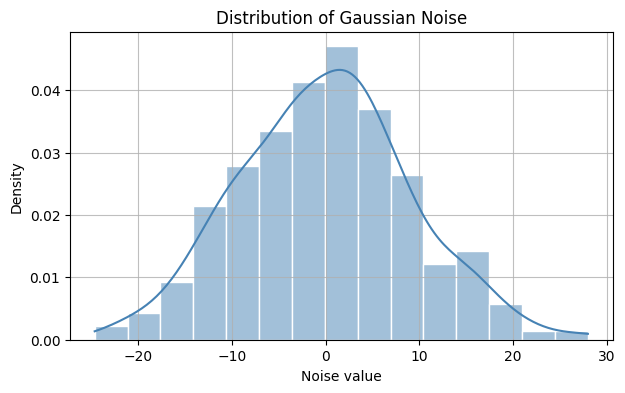

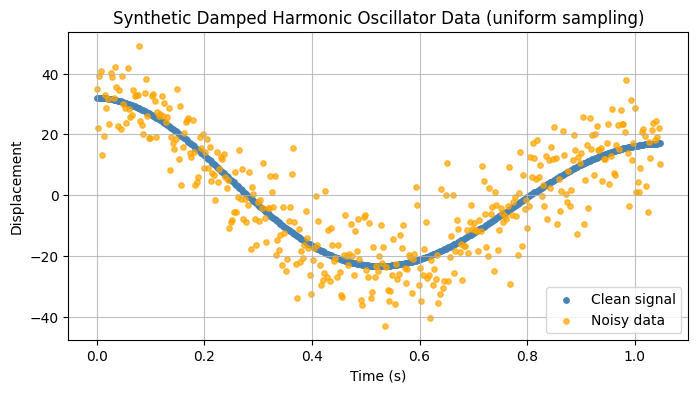

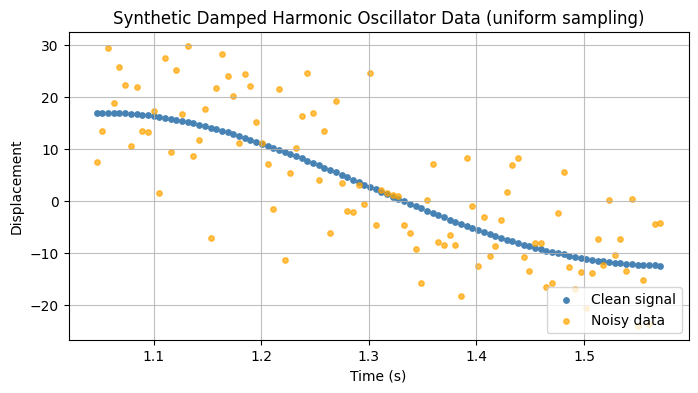

In [31]:
data = generate_data(cfg, plot=True)

#### Training both models

**Model 1: plain ANN (data only).** The network only sees the noisy observations. It minimizes

$$\mathcal{L}_{ANN} = \frac{1}{N}\sum_{i=1}^{N}\left(\hat{x}(t_i) - x_i^{noisy}\right)^2$$

Nothing tells it that the signal is an oscillator, so outside the training window it has no information to rely on.

**Model 2: PINN.** Same architecture, same data, same initial weights. The loss now also includes physics:

$$\mathcal{L}_{PINN} = \underbrace{\frac{1}{N}\sum_{i=1}^{N}\left(\hat{x}(t_i) - x_i^{noisy}\right)^2}_{\mathcal{L}_{data}}
+ \lambda_{phys}\underbrace{\frac{1}{M}\sum_{j=1}^{M}r(t_j)^2}_{\mathcal{L}_{phys}}
+ \lambda_{IC}\underbrace{\left[(\hat{x}(0)-x_0)^2 + (\dot{\hat{x}}(0)-v_0)^2\right]}_{\mathcal{L}_{IC}}$$

with the ODE residual
$$r(t) = \ddot{\hat{x}} + 2\zeta\omega\dot{\hat{x}} + \omega^2\hat{x}$$

- $\mathcal{L}_{phys}$ is evaluated on **collocation points** $t_j$. These don't need measurements, so they can extend beyond the data window (`colloc_t_end`, or `colloc_test_window=True` to cover the whole test window).
- $\mathcal{L}_{IC}$ uses the known initial state of the oscillator.

In [32]:
res = run_experiment(cfg, verbose=True)
print(res.model_ann)

[uniform] Training ANN ...
Epoch 300/1500, Loss: 0.213620
Epoch 600/1500, Loss: 0.210181
Epoch 900/1500, Loss: 0.209998
Epoch 1200/1500, Loss: 0.209889
Epoch 1500/1500, Loss: 0.209786
[uniform] Training PINN ...
Epoch 5000/50000 | Total: 1.96515 | Data: 0.95785 | Physics: 41.11324 | IC: 966.18561
Epoch 10000/50000 | Total: 1.85965 | Data: 0.89697 | Physics: 85.86720 | IC: 876.81354
Epoch 15000/50000 | Total: 0.22064 | Data: 0.21331 | Physics: 6.23055 | IC: 1.10578
Epoch 20000/50000 | Total: 0.21401 | Data: 0.21200 | Physics: 2.00259 | IC: 0.01073
Epoch 25000/50000 | Total: 0.21346 | Data: 0.21196 | Physics: 1.48084 | IC: 0.01304
Epoch 30000/50000 | Total: 0.21322 | Data: 0.21195 | Physics: 1.25033 | IC: 0.01770
Epoch 35000/50000 | Total: 0.21305 | Data: 0.21195 | Physics: 1.08364 | IC: 0.01894
Epoch 40000/50000 | Total: 0.21293 | Data: 0.21195 | Physics: 0.96727 | IC: 0.02017
Epoch 45000/50000 | Total: 0.21284 | Data: 0.21195 | Physics: 0.87765 | IC: 0.01985
Epoch 50000/50000 | Total: 

### 3.1 Model 1 — Plain ANN

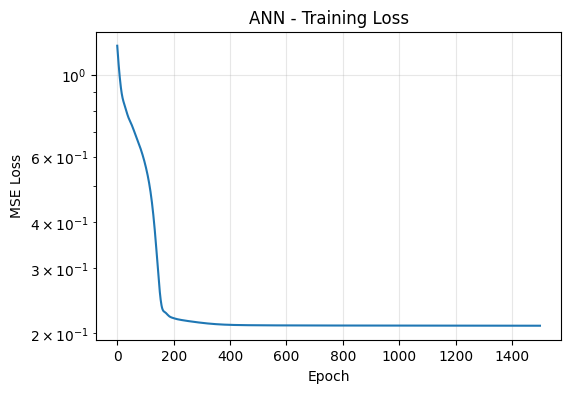

In [33]:
plot_ann_loss(res)

#### Training set fit

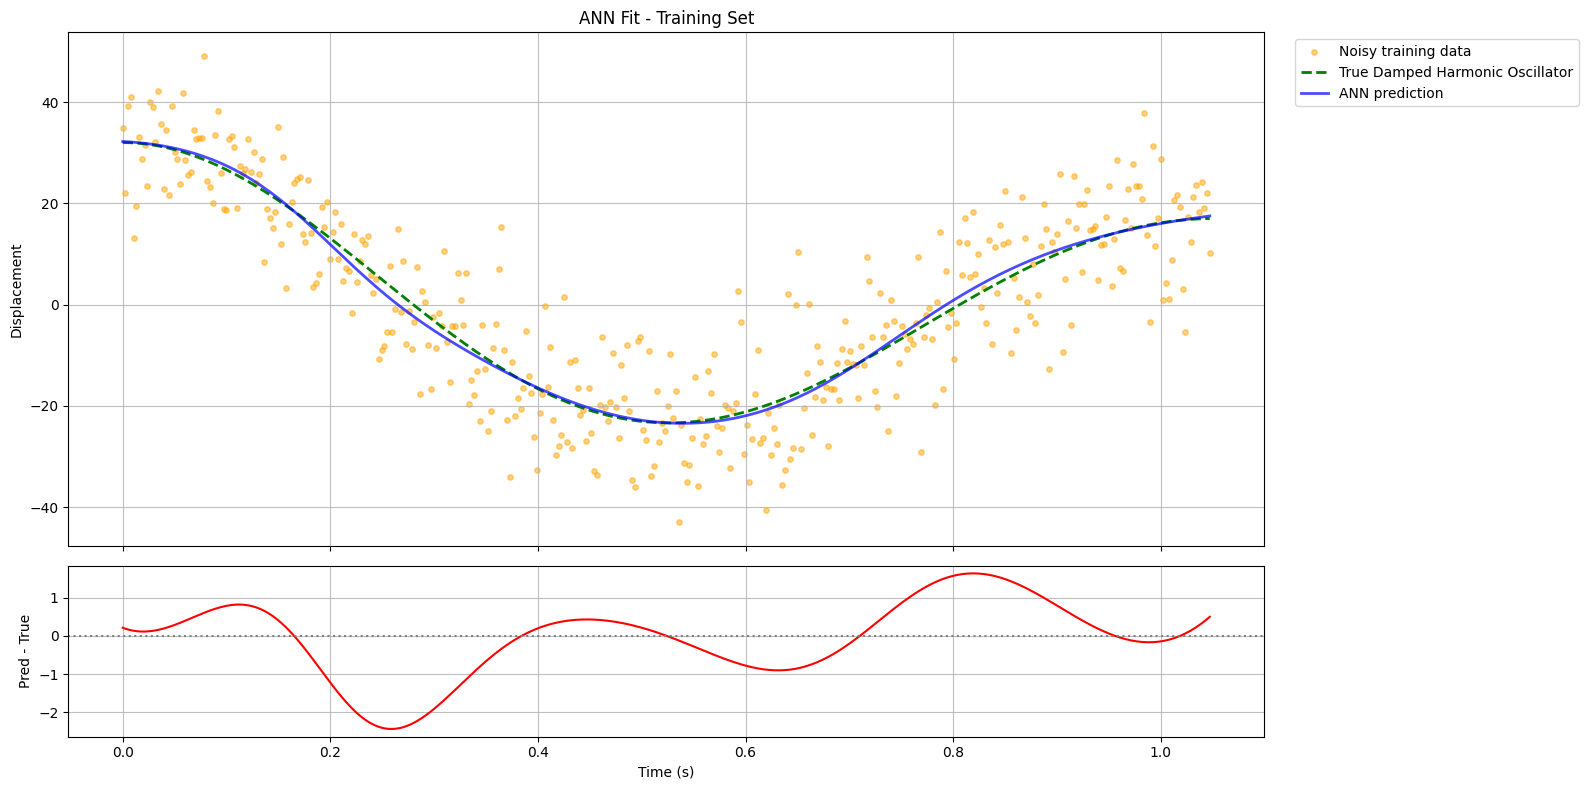

In [34]:
plot_model_fit(res, "ann", "train")

#### Test set (forecasting)

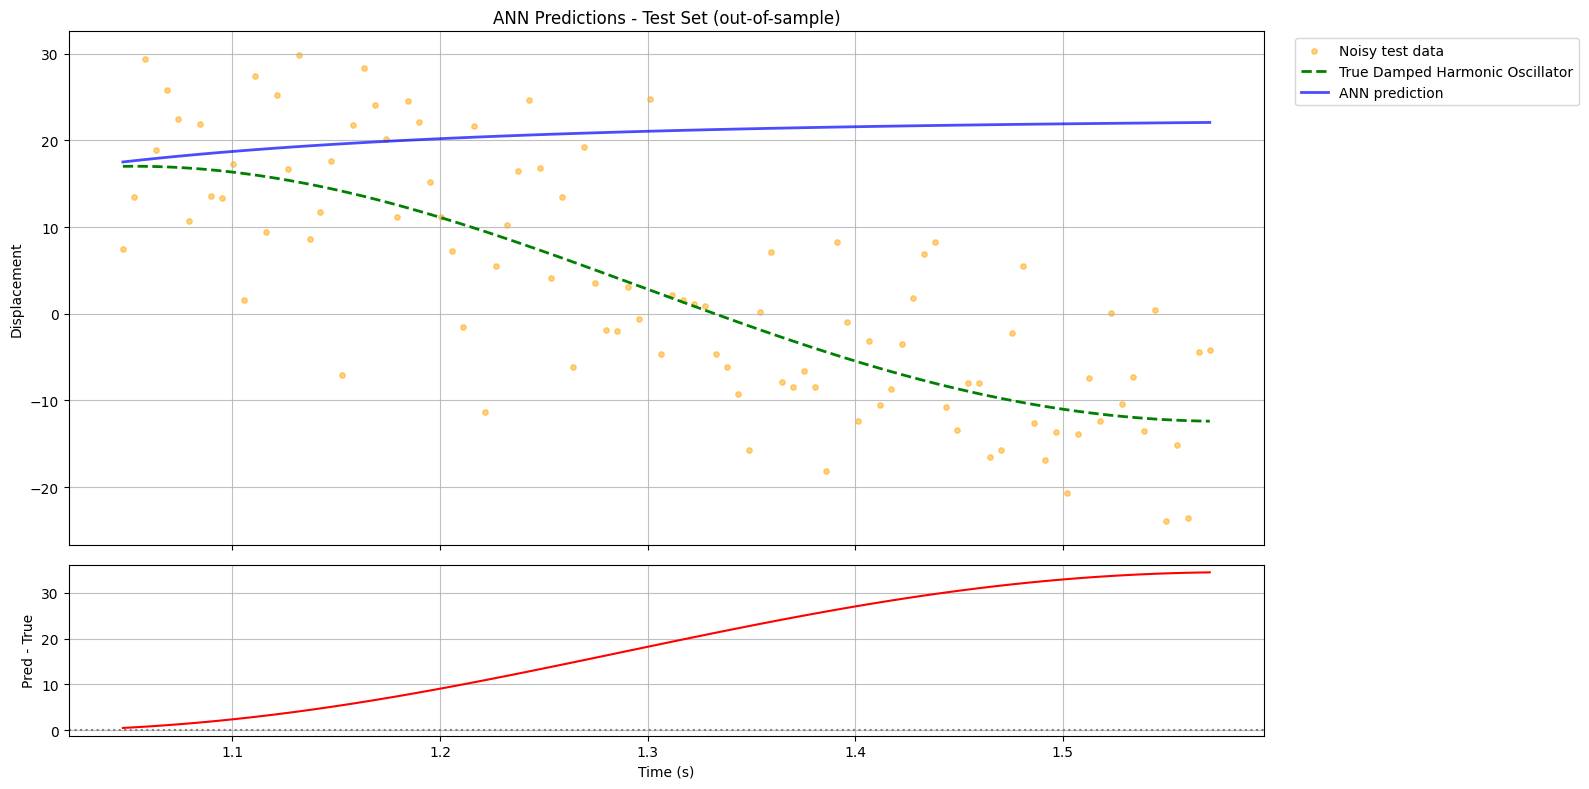

In [35]:
plot_model_fit(res, "ann", "test")

### 3.2 Model 2 — PINN

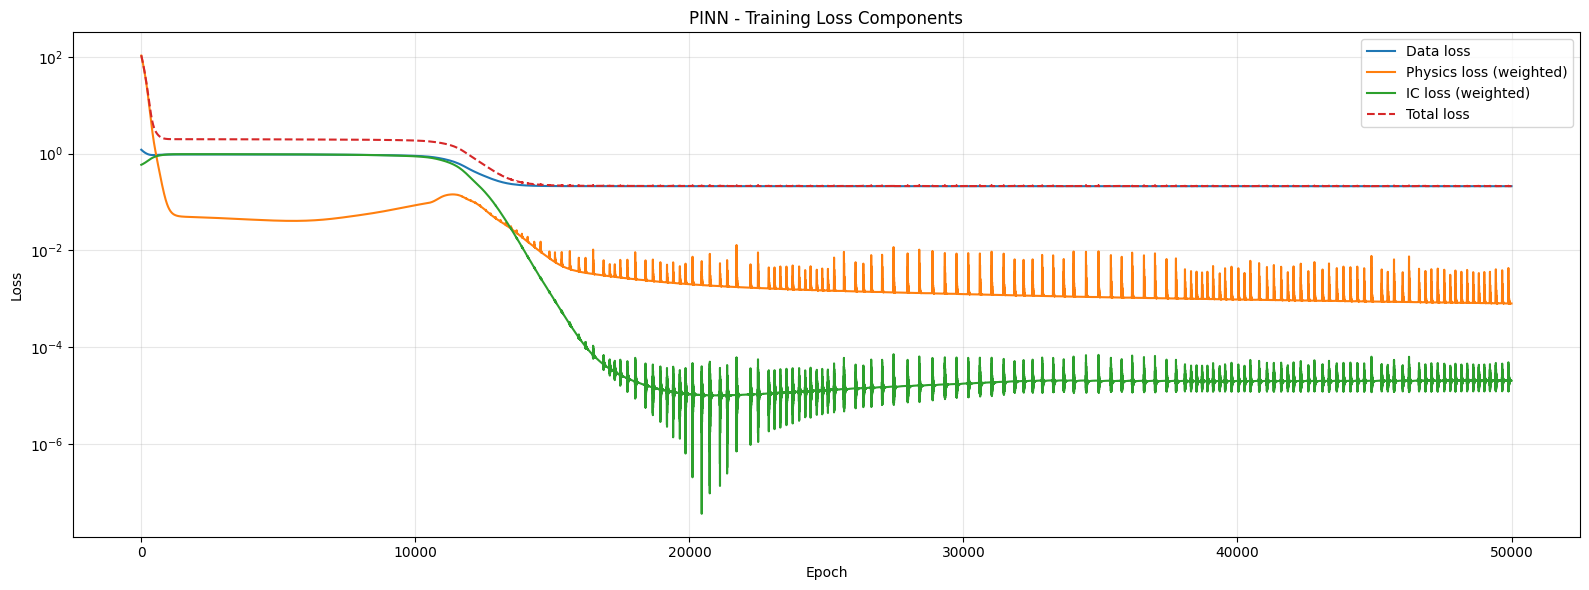

In [36]:
plot_pinn_losses(res)

#### Training set fit

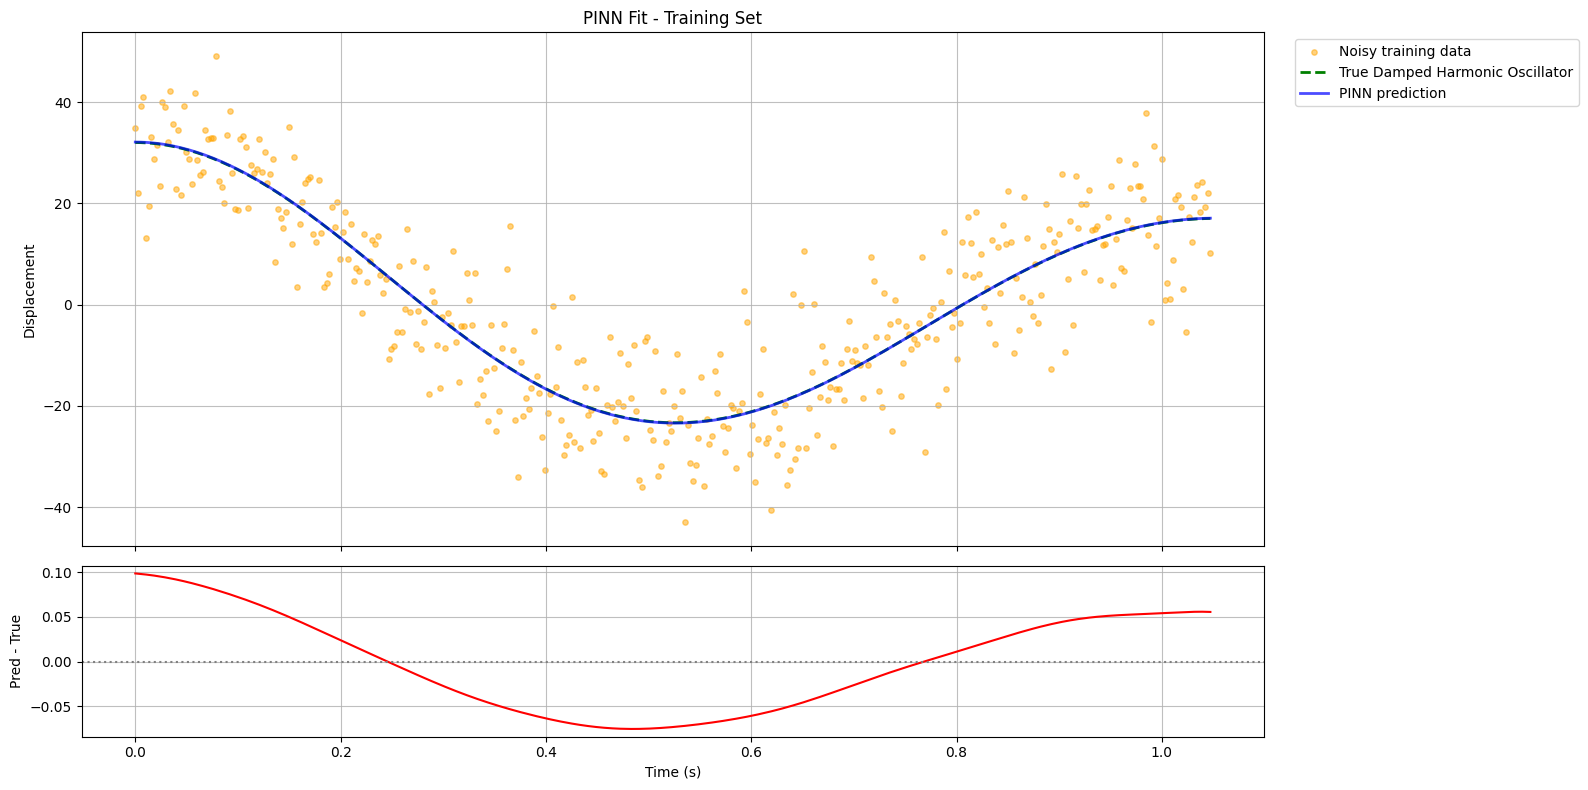

In [37]:
plot_model_fit(res, "pinn", "train")

#### Test set (forecasting)

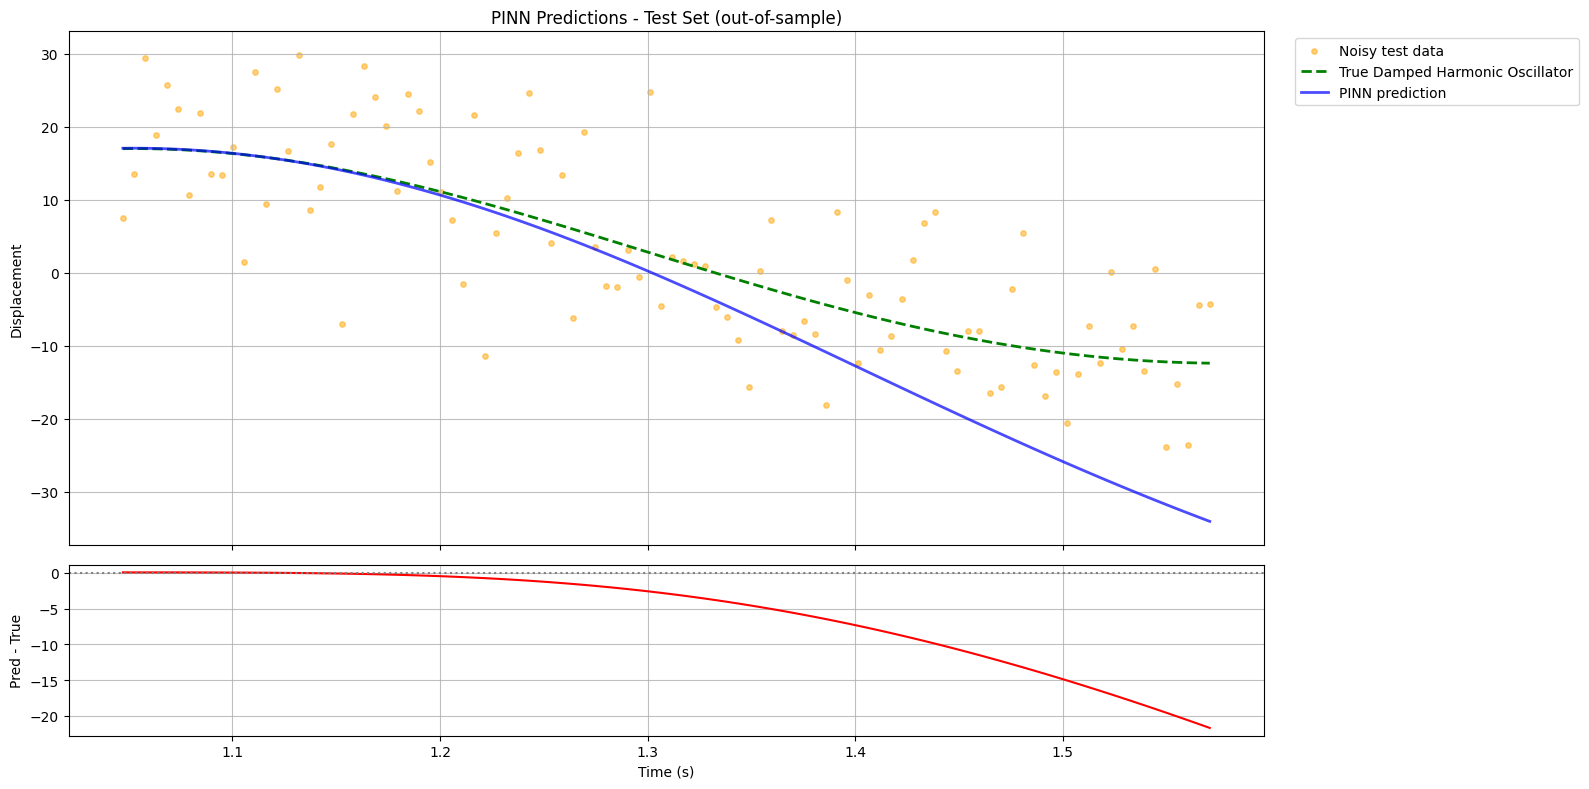

In [38]:
plot_model_fit(res, "pinn", "test")

### 3.3 ANN vs PINN — head-to-head

Several views of the same question: *did the model learn the oscillator, or just the data?*
1. **Data loss vs noise floor:** how closely each model chases the noisy points.
2. **Predictions over training + test windows.**
3. **Prediction error over time**, against the true signal.
4. **Physical consistency:** how well each model satisfies the ODE.
5. **Phase portrait** $(x, \dot{x})$.
6. **Power spectrum:** which frequencies each model reproduces.
7. **Metrics table.**

#### 1. Data loss vs noise floor
With independent Gaussian noise, a model that recovers the *true* signal cannot push the data MSE below the noise variance (in normalized units: $(\sigma_{noise}/\sigma_x)^2$). A data loss **below** this floor means the model is fitting the noise.

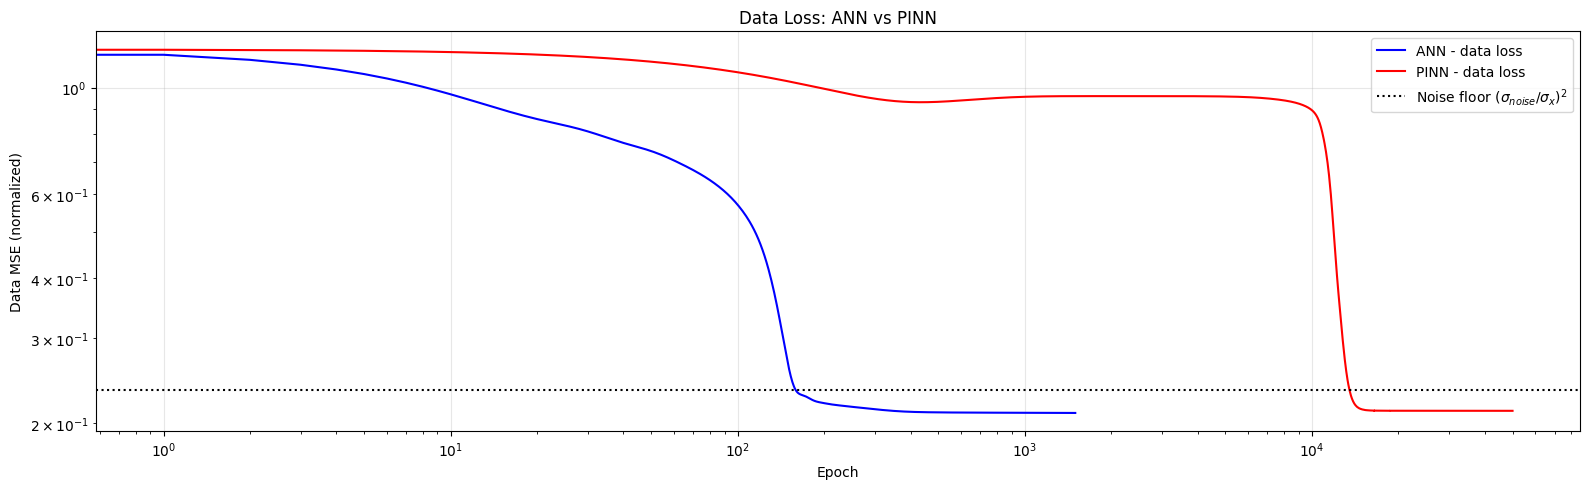

In [39]:
plot_data_loss_vs_noise_floor(res)

#### 2. Predictions over training + test windows

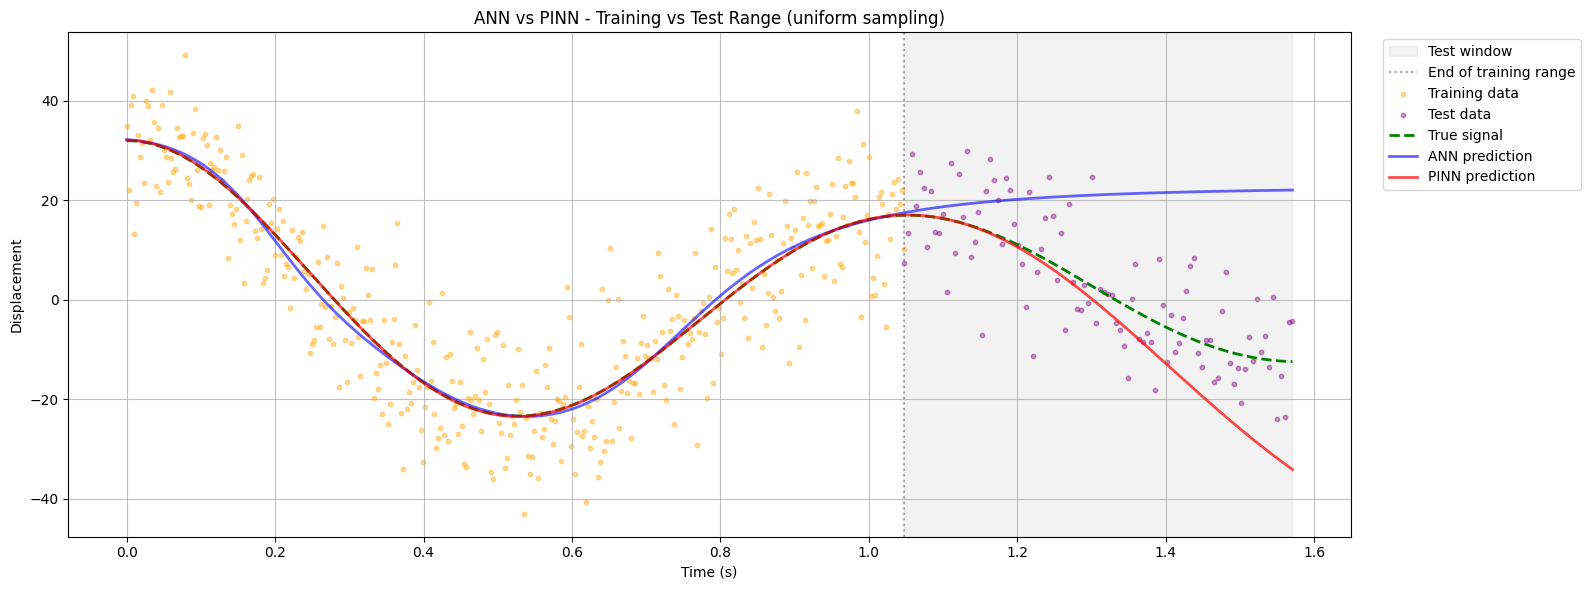

In [40]:
plot_predictions_full(res)

#### 3. Prediction error over time (vs true signal)

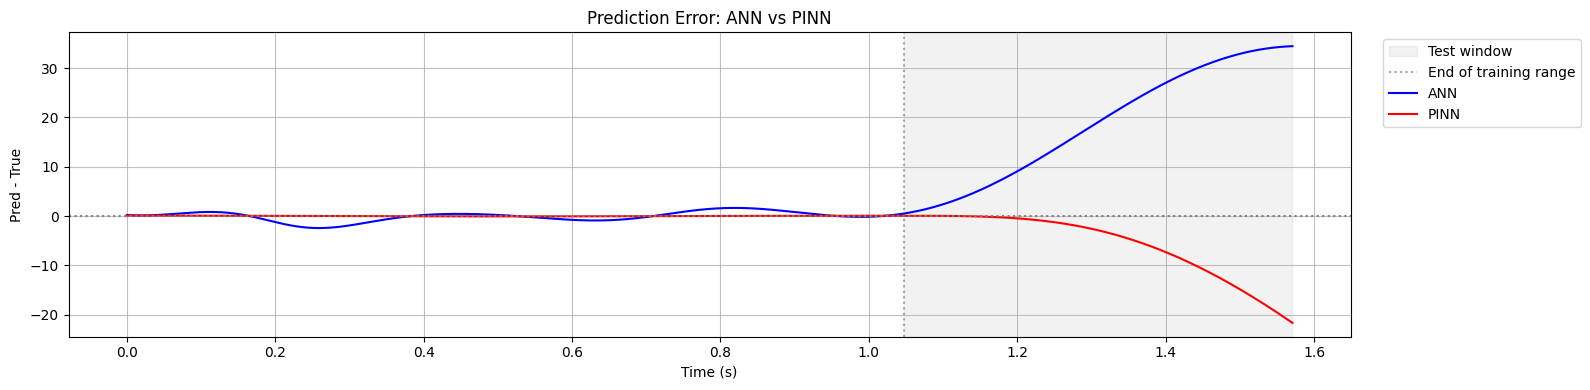

In [41]:
plot_error_full(res)

#### 4. Physical consistency
Evaluate the ODE residual $r(t) = \ddot{\hat{x}} + 2\zeta\omega\dot{\hat{x}} + \omega^2\hat{x}$ of **both** trained models over the full time range. The true solution has $r(t) = 0$ everywhere. The ANN was never asked to satisfy this, so it measures how "physical" a purely data-driven fit is.

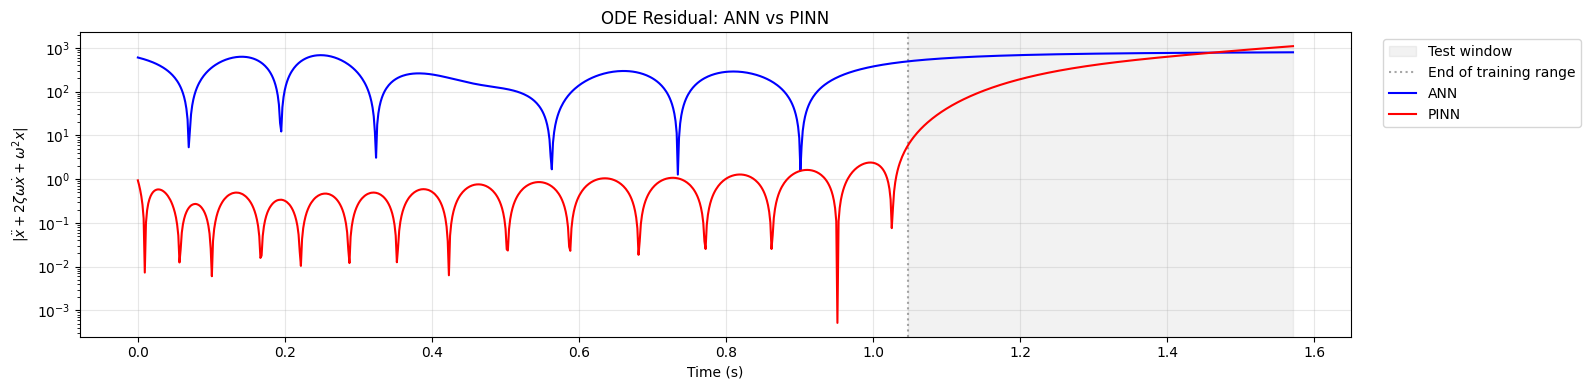

In [42]:
plot_ode_residual(res)

#### 5. Phase portrait
Velocities $\dot{\hat{x}}(t)$ of the networks come from autograd; the true one is analytic. The true trajectory is a spiral converging to the origin: a model that learned the damping must spiral inwards at the right rate.

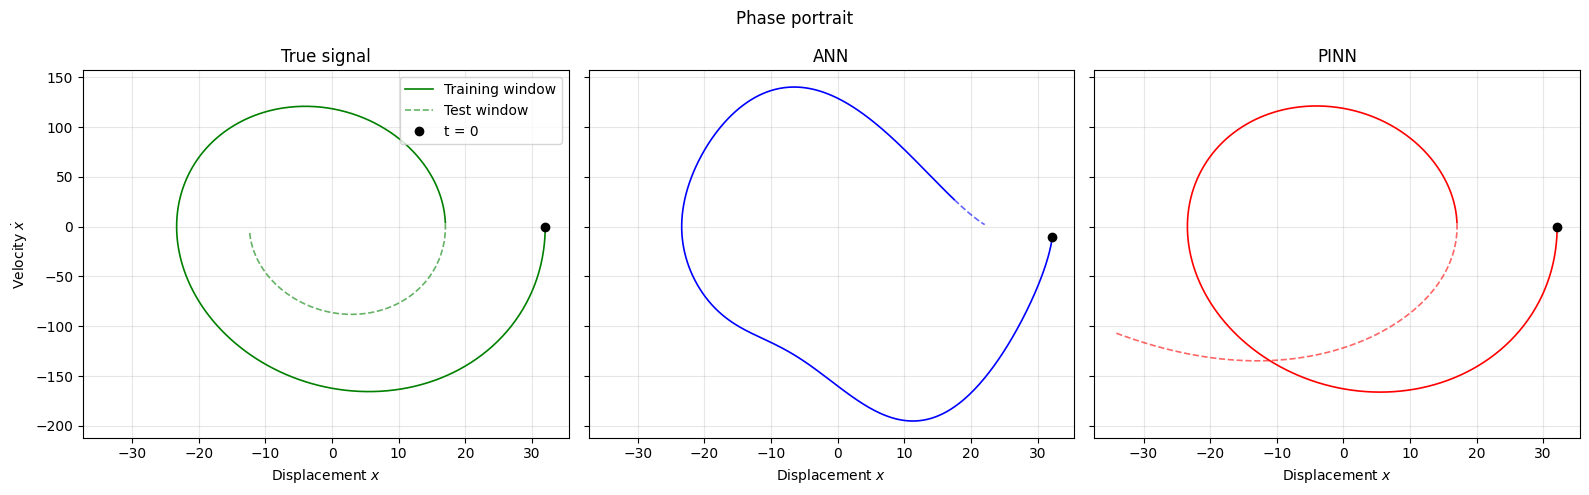

In [43]:
plot_phase_portrait(res)

#### 7. Metrics

In [44]:
display(res.metrics.round(4))
display(res.physics_rms.to_frame().round(4))

ANN                                PINN           \
                       MSE     RMSE      MAE      R2       MSE     RMSE   
Train (vs noisy)   82.5025   9.0831   7.1941  0.7897   83.3520   9.1297   
Train (vs true)     0.9638   0.9817   0.7458  0.9968    0.0029   0.0537   
Test (vs noisy)   529.1484  23.0032  19.3602 -1.7841  157.6038  12.5540   
Test (vs true)    475.6863  21.8102  18.4682 -3.3678   75.4185   8.6844   

                                  
                     MAE      R2  
Train (vs noisy)  7.2683  0.7875  
Train (vs true)   0.0477  1.0000  
Test (vs noisy)   9.8403  0.1708  
Test (vs true)    5.7788  0.3075

,ODE residual RMS
ANN,480.321014
PINN,322.358185


### 3.4 Enforcing the physics over the forecast window

The PINN above only evaluates the ODE on the training window, so in the test window it extrapolates just like the ANN (only better initialized by the physics). Collocation points need **no measurements**, so we can also place them over the test window: the PINN is then *solving the ODE forward*, anchored by the data and the initial conditions. The ANN has no equivalent. Same data, same weights, only `colloc_test_window=True`.

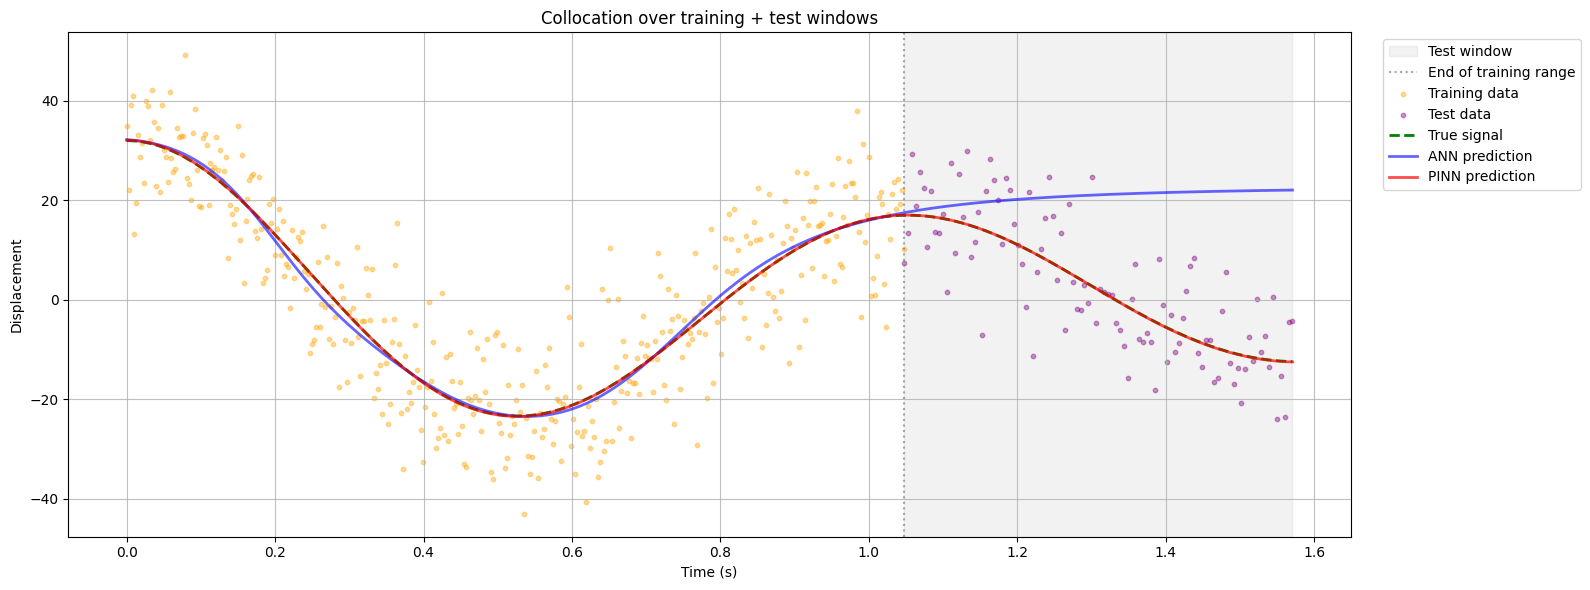

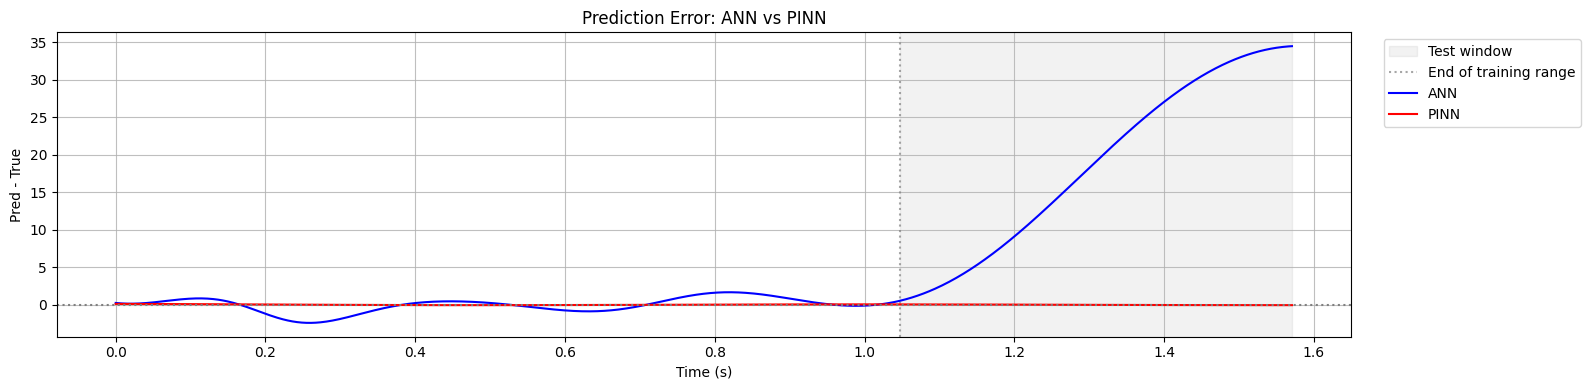

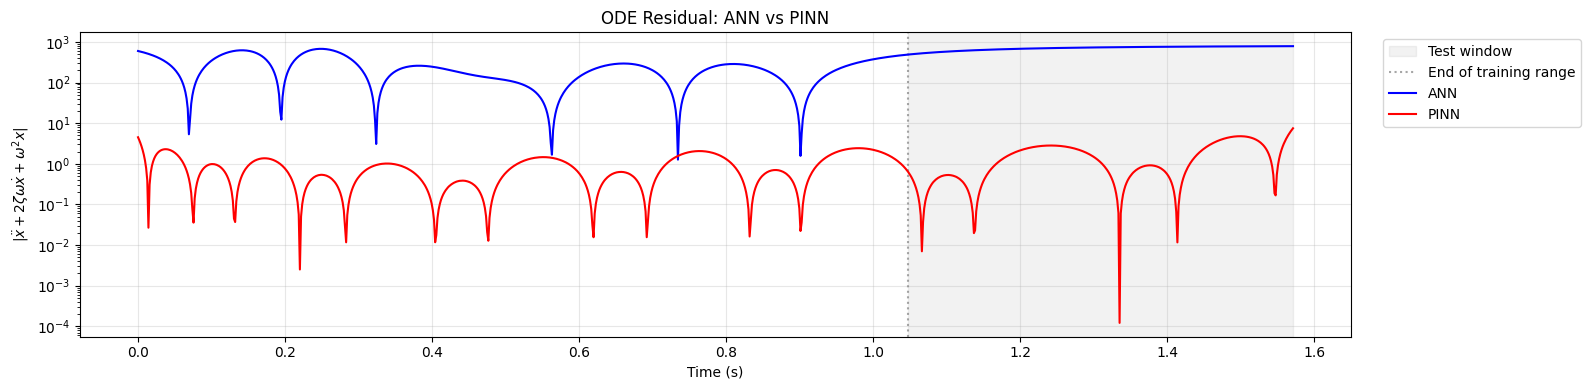

,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS
,ANN,ANN,ANN,ANN,PINN,PINN,PINN,PINN
collocation: training window,0.9817,21.8102,-3.3678,480.321014,0.0537,8.6844,0.3075,322.358185
collocation: training + test window,0.9817,21.8102,-3.3678,480.321014,0.0505,0.0478,1.0000,1.595200


In [45]:
cfg_ext = replace(cfg, colloc_test_window=True)
res_ext = run_experiment(cfg_ext, verbose=False)

plot_predictions_full(res_ext, title="Collocation over training + test windows")
plot_error_full(res_ext)
plot_ode_residual(res_ext)
display(summarize({"collocation: training window": res,
                   "collocation: training + test window": res_ext}).round(4))

## 4. Loss-weight sweep: varying $\lambda_{phys}$

Same data (the `cfg` of Section 3), same initial weights, same optimizer, learning rate and number of epochs: the **only** thing that changes between runs is the weight of the physics term

$$\mathcal{L} = \mathcal{L}_{data} + \lambda_{phys}\,\mathcal{L}_{phys} + \lambda_{IC}\,\mathcal{L}_{IC}$$

- **ANN ($\lambda_{phys} = 0$):** with $\lambda_{phys} = \lambda_{IC} = 0$ the PINN loss reduces to the data MSE, i.e. a plain ANN. Note that it is trained with the PINN recipe (`pinn_lr`, `pinn_epochs`), not the ANN recipe of Section 3, so along the sweep nothing but the loss changes.
- **IC only ($\lambda_{phys} = 0$, $\lambda_{IC}$ = `cfg.lambda_ic`):** control run, separates the effect of the initial conditions from the ODE.
- **$\lambda_{phys} > 0$:** log-spaced values, with $\lambda_{IC}$ fixed at `cfg.lambda_ic`.

**Scales.** $\mathcal{L}_{data}$ is computed in normalized units (order 1, noise floor $(\sigma_{noise}/\sigma_x)^2$), while $\mathcal{L}_{phys}$ is in physical units: for an untrained network it is of order $(\omega^2 A)^2 \approx 10^6$. The two terms balance at a small $\lambda_{phys}$, which is why the range starts at $10^{-6}$.

Collocation points cover only the training window (`colloc_test_window=False`), so the test window is pure extrapolation for every run. Each run takes ~2–3 min on CPU.

In [46]:
lambda_values = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]

lambda_variants = {
    "ANN (λ_phys = 0, λ_IC = 0)": dict(lambda_physics=0.0, lambda_ic=0.0),
    "IC only (λ_phys = 0)":       dict(lambda_physics=0.0),
    **{f"λ_phys = {lam:g}": dict(lambda_physics=lam) for lam in lambda_values},
}

lambda_runs, lambda_summary = sweep_pinn(cfg, lambda_variants)

Running ANN (λ_phys = 0, λ_IC = 0) ...
Running IC only (λ_phys = 0) ...
Running λ_phys = 1e-06 ...
Running λ_phys = 1e-05 ...
Running λ_phys = 0.0001 ...
Running λ_phys = 0.001 ...
Running λ_phys = 0.01 ...
Running λ_phys = 0.1 ...
Running λ_phys = 1 ...
Running λ_phys = 10 ...


#### Summary (metrics against the true signal unless stated)

In [47]:
display(lambda_summary.round(4))

,lambda_physics,lambda_ic,Final data loss,Final physics loss,Final IC loss,Train RMSE (vs noisy),Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS (train window),ODE residual RMS (test window)
"ANN (λ_phys = 0, λ_IC = 0)",0.0000,0.000,0.1461,2.928378e+12,3.547472e+07,7.5800,4.9958,16.5663,-1.5200,1.870301e+06,563.863708
IC only (λ_phys = 0),0.0000,0.001,0.1824,4.002293e+10,4.200000e-03,8.4703,3.3160,32.8090,-8.8839,2.000830e+05,1121.894409
λ_phys = 1e-06,0.0000,0.001,0.2110,1.978041e+02,4.400000e-03,9.1100,0.4779,9.3780,0.1925,1.406830e+01,331.408813
λ_phys = 1e-05,0.0000,0.001,0.2115,1.773370e+01,1.580000e-02,9.1201,0.2236,8.6102,0.3193,4.281800e+00,302.093201
λ_phys = 0.0001,0.0001,0.001,0.2118,2.919900e+00,1.320000e-02,9.1286,0.0912,4.6763,0.7992,1.726100e+00,359.979706
λ_phys = 0.001,0.0010,0.001,0.2119,8.006000e-01,2.040000e-02,9.1297,0.0537,8.6844,0.3075,8.709000e-01,557.781982
λ_phys = 0.01,0.0100,0.001,0.2139,4.007100e+00,1.745800e+00,9.1720,0.6955,10.6047,-0.0326,1.971800e+00,717.188782
λ_phys = 0.1,0.1000,0.001,0.9618,1.004000e-01,9.756965e+02,19.4490,17.0112,10.2208,0.0408,3.163000e-01,27.670700
λ_phys = 1,1.0000,0.001,0.9957,9.000000e-04,1.020835e+03,19.7885,17.3921,10.6453,-0.0406,3.070000e-02,1.497500
λ_phys = 10,10.0000,0.001,0.9980,3.000000e-04,1.023891e+03,19.8116,17.4181,10.6744,-0.0462,1.840000e-02,0.353200


#### Predictions for each $\lambda_{phys}$

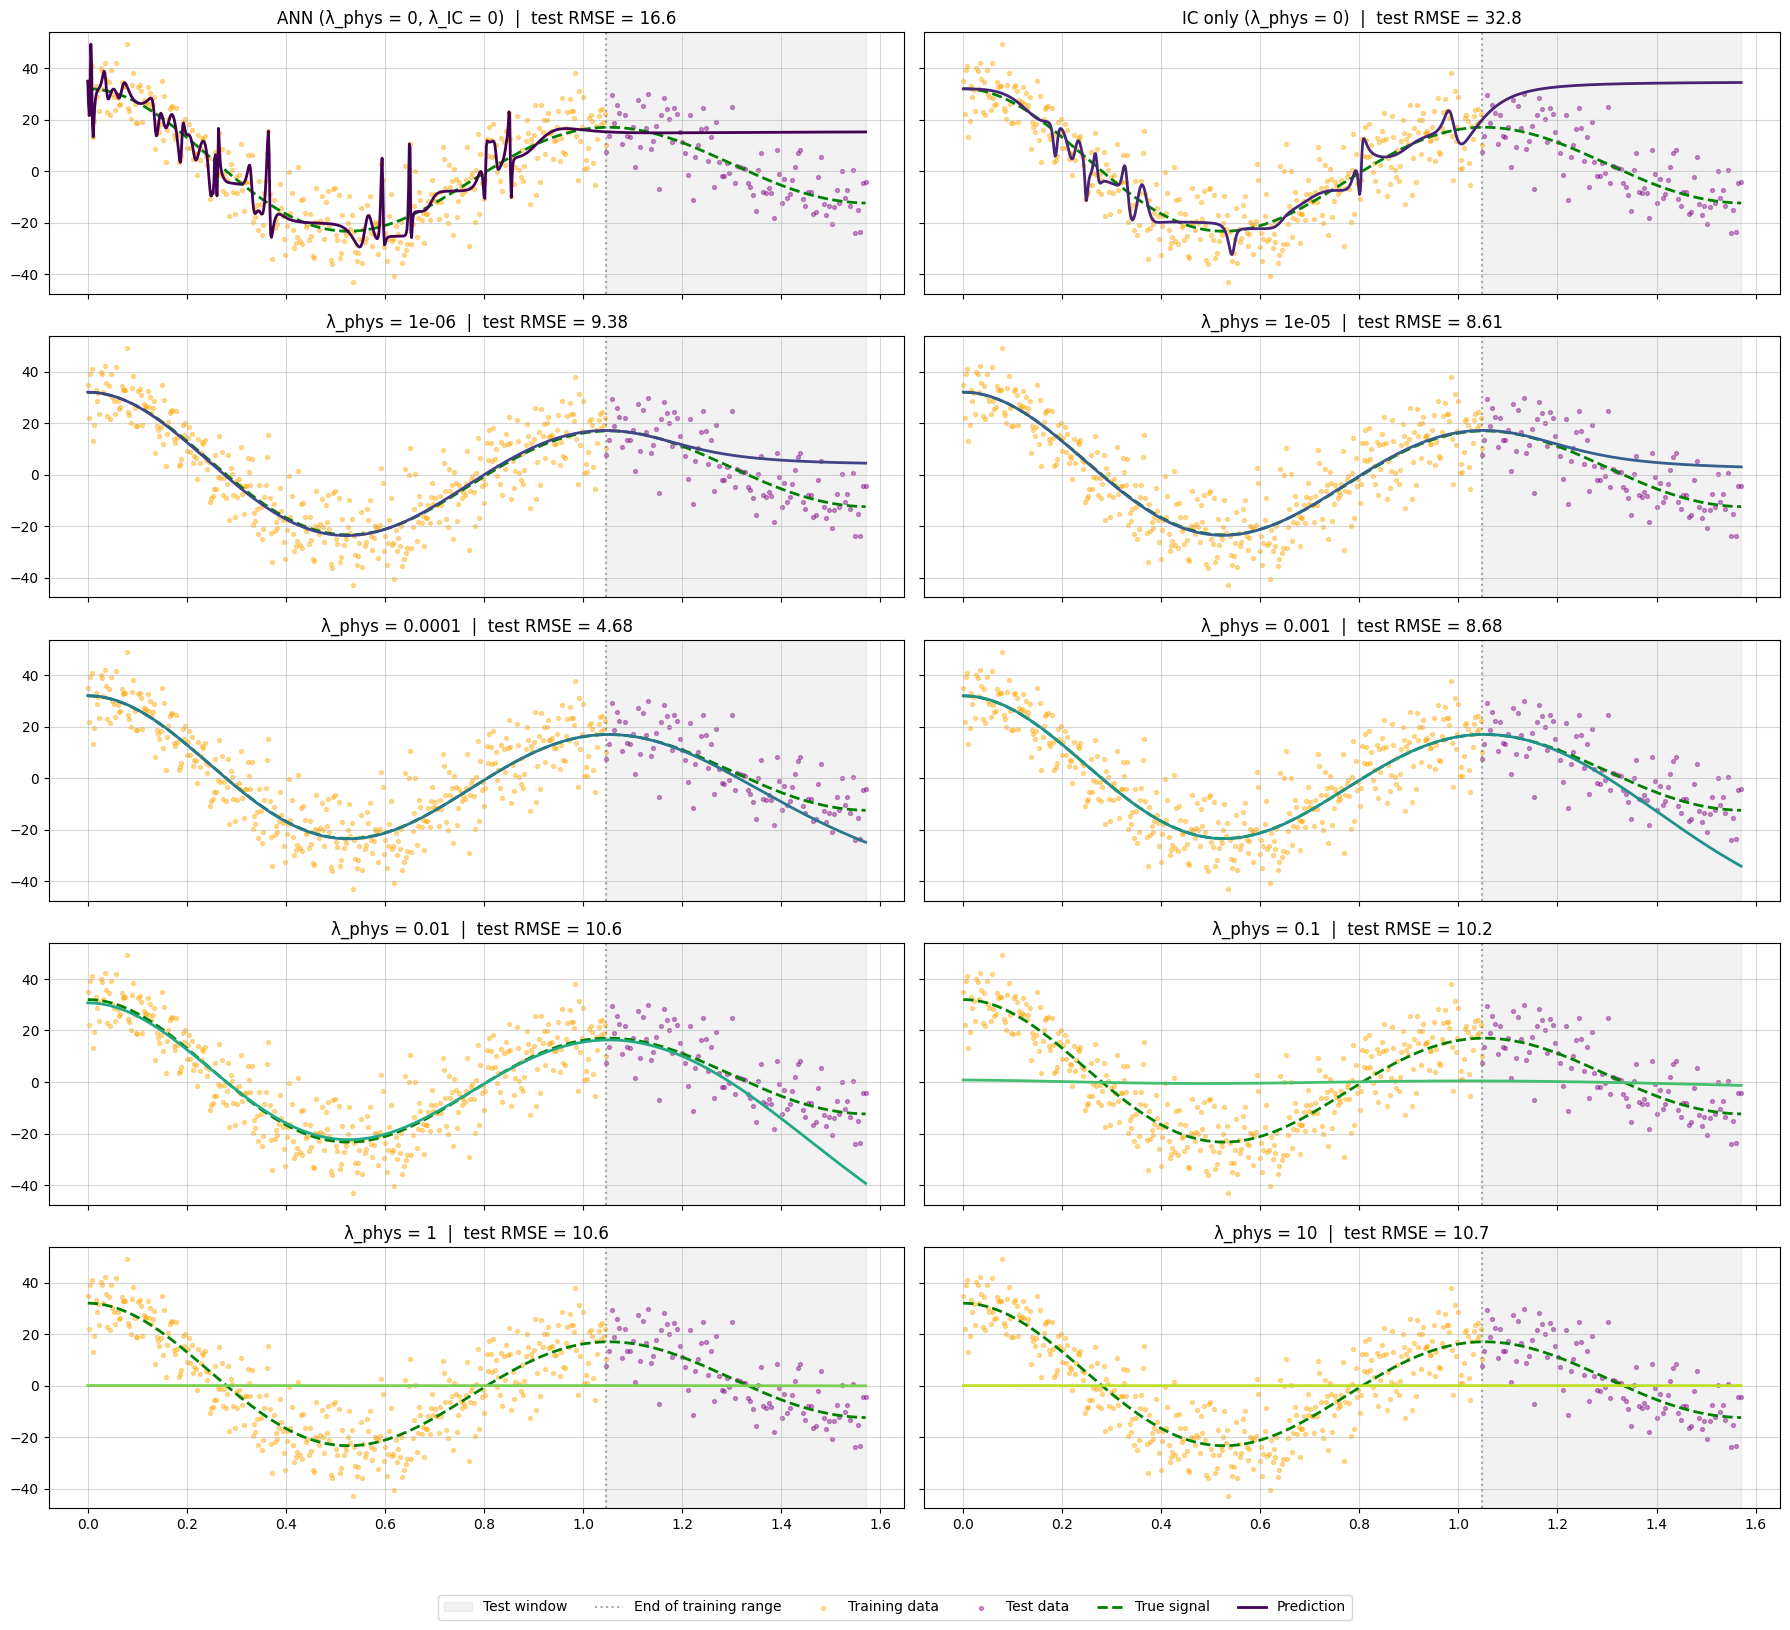

In [48]:
plot_sweep_predictions(lambda_runs, ncols=2)

#### Prediction error over time

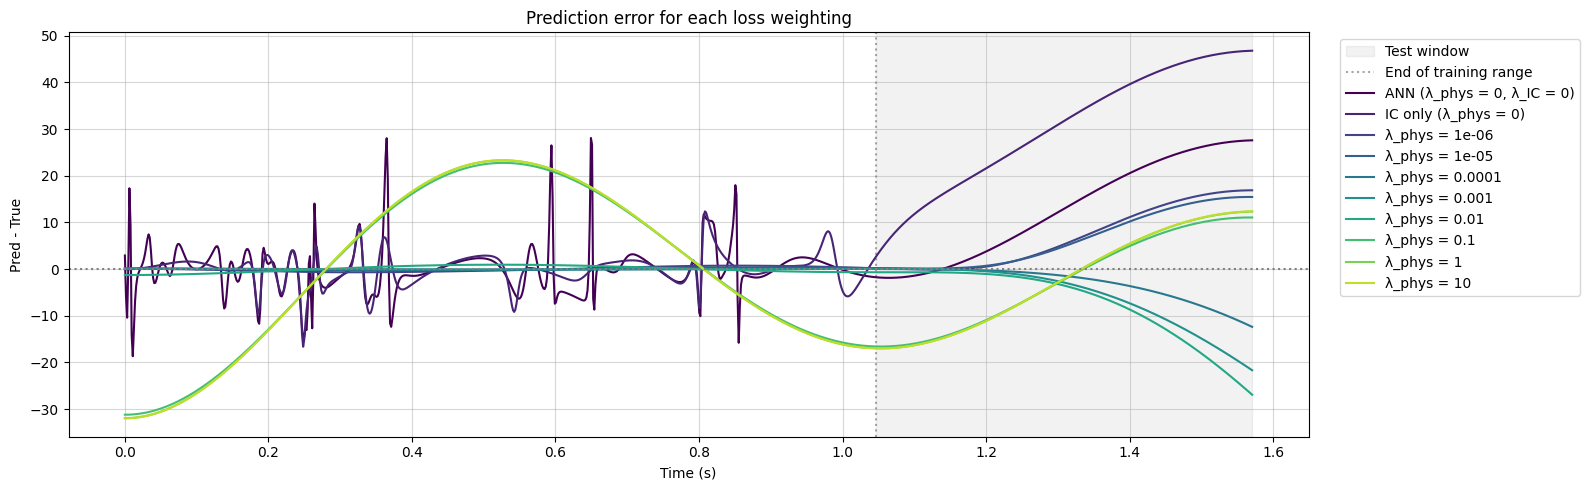

In [49]:
plot_sweep_errors(lambda_runs)

#### Training curves
Data loss against the noise floor, and the (unweighted) physics loss on the collocation points.

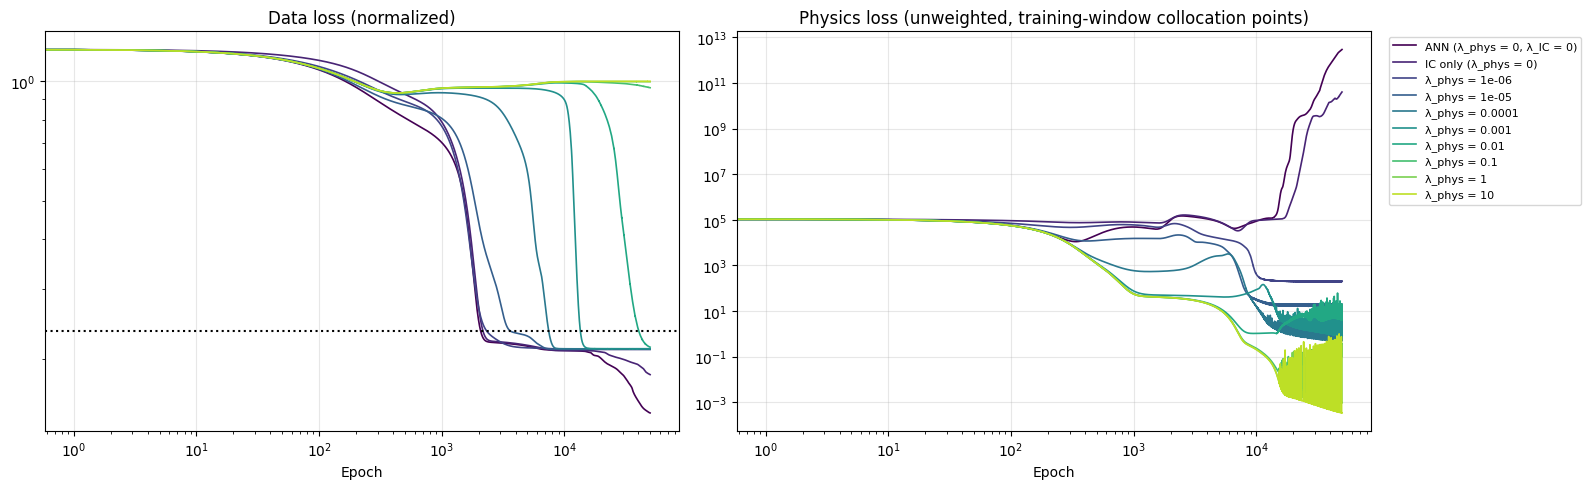

In [50]:
plot_sweep_losses(lambda_runs)

## 5. Sampling-scheme sweep

Same oscillator, same noise, same test set, same initial weights: only the **training time sampling** changes. Each scheme trains one ANN and one PINN, so the cost is `len(schemes)` × (ANN + PINN) trainings (about 2.5 min per scheme on CPU). Lower `pinn_epochs` in `sweep_cfg` for a quick first look, and set `colloc_test_window=True` to sweep the setting of Section 3.4 instead.

In [22]:
sweep_cfg = replace(base_cfg, pinn_epochs=30_000)
sweep_schemes = schemes  # or a subset, e.g. {k: schemes[k] for k in ["uniform", "gaps", "clustered"]}

results, summary = compare_sampling_schemes(sweep_cfg, sweep_schemes)

Running uniform ...
Running random ...
Running chebyshev ...
Running beta(0.5, 0.5) ends ...
Running beta(2, 2) centre ...
Running normal ...
Running exponential start ...
Running exponential end ...
Running log ...
Running jitter ...
Running gaps ...
Running clustered ...


#### Summary (all metrics against the true signal)

In [23]:
display(summary.round(4))

,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS,Train RMSE (vs true),Test RMSE (vs true),Test R2 (vs true),ODE residual RMS
,ANN,ANN,ANN,ANN,PINN,PINN,PINN,PINN
uniform,0.9817,21.8102,-3.3678,480.321014,0.0479,8.8390,0.2826,316.740601
random,1.0348,22.4143,-3.6131,492.285004,0.0741,8.6892,0.3067,316.506989
chebyshev,0.9806,21.5152,-3.2505,457.198395,0.0990,10.1565,0.0528,375.750793
"beta(0.5, 0.5) ends",0.9493,22.1784,-3.5166,460.190704,0.0816,10.1858,0.0473,375.075195
"beta(2, 2) centre",0.9590,24.0625,-4.3165,551.831970,0.0826,5.8290,0.6880,233.849503
normal,0.9476,22.7285,-3.7434,488.735413,0.0503,5.2899,0.7431,199.184799
exponential start,0.8305,21.0687,-3.0759,453.635590,0.2524,5.8371,0.6871,259.737793
exponential end,0.9428,9.9097,0.0983,295.807587,0.2090,3.7763,0.8691,174.071304
log,1.2813,28.7090,-6.5680,658.295288,0.4798,3.5766,0.8825,204.761093


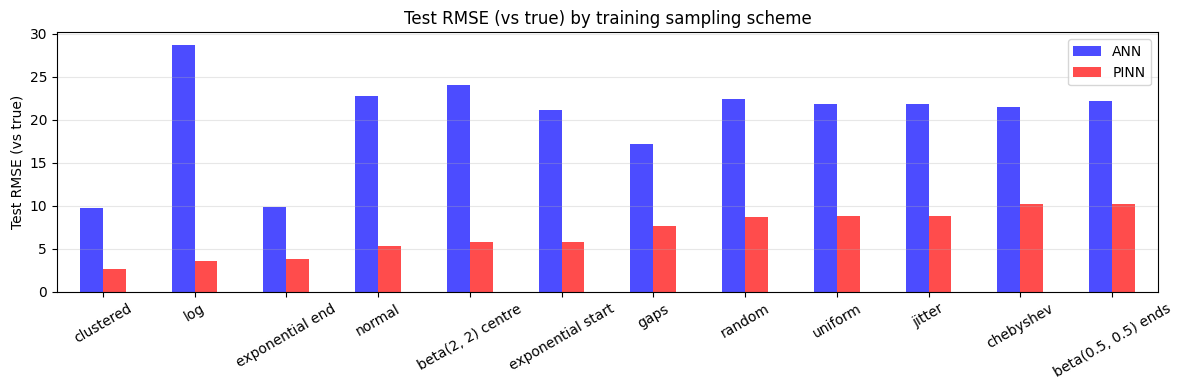

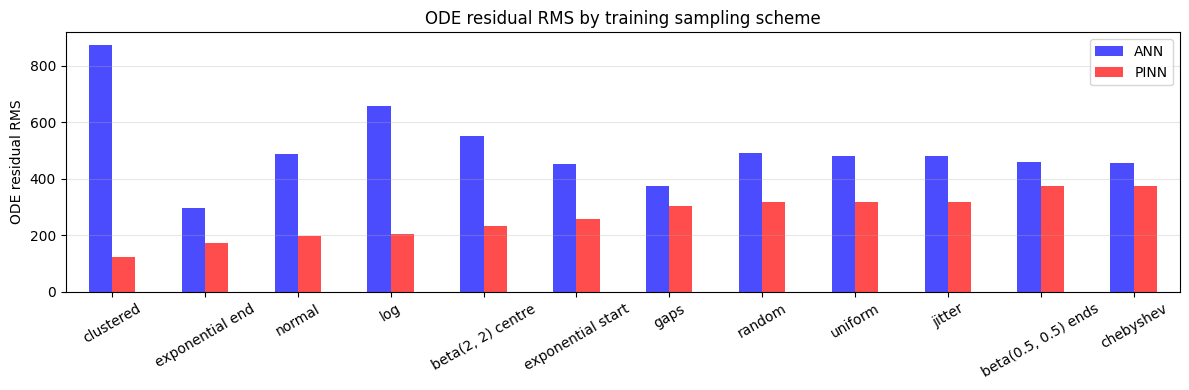

In [24]:
plot_summary_bars(summary, "Test RMSE (vs true)")
plot_summary_bars(summary, "ODE residual RMS")

#### Predictions per scheme

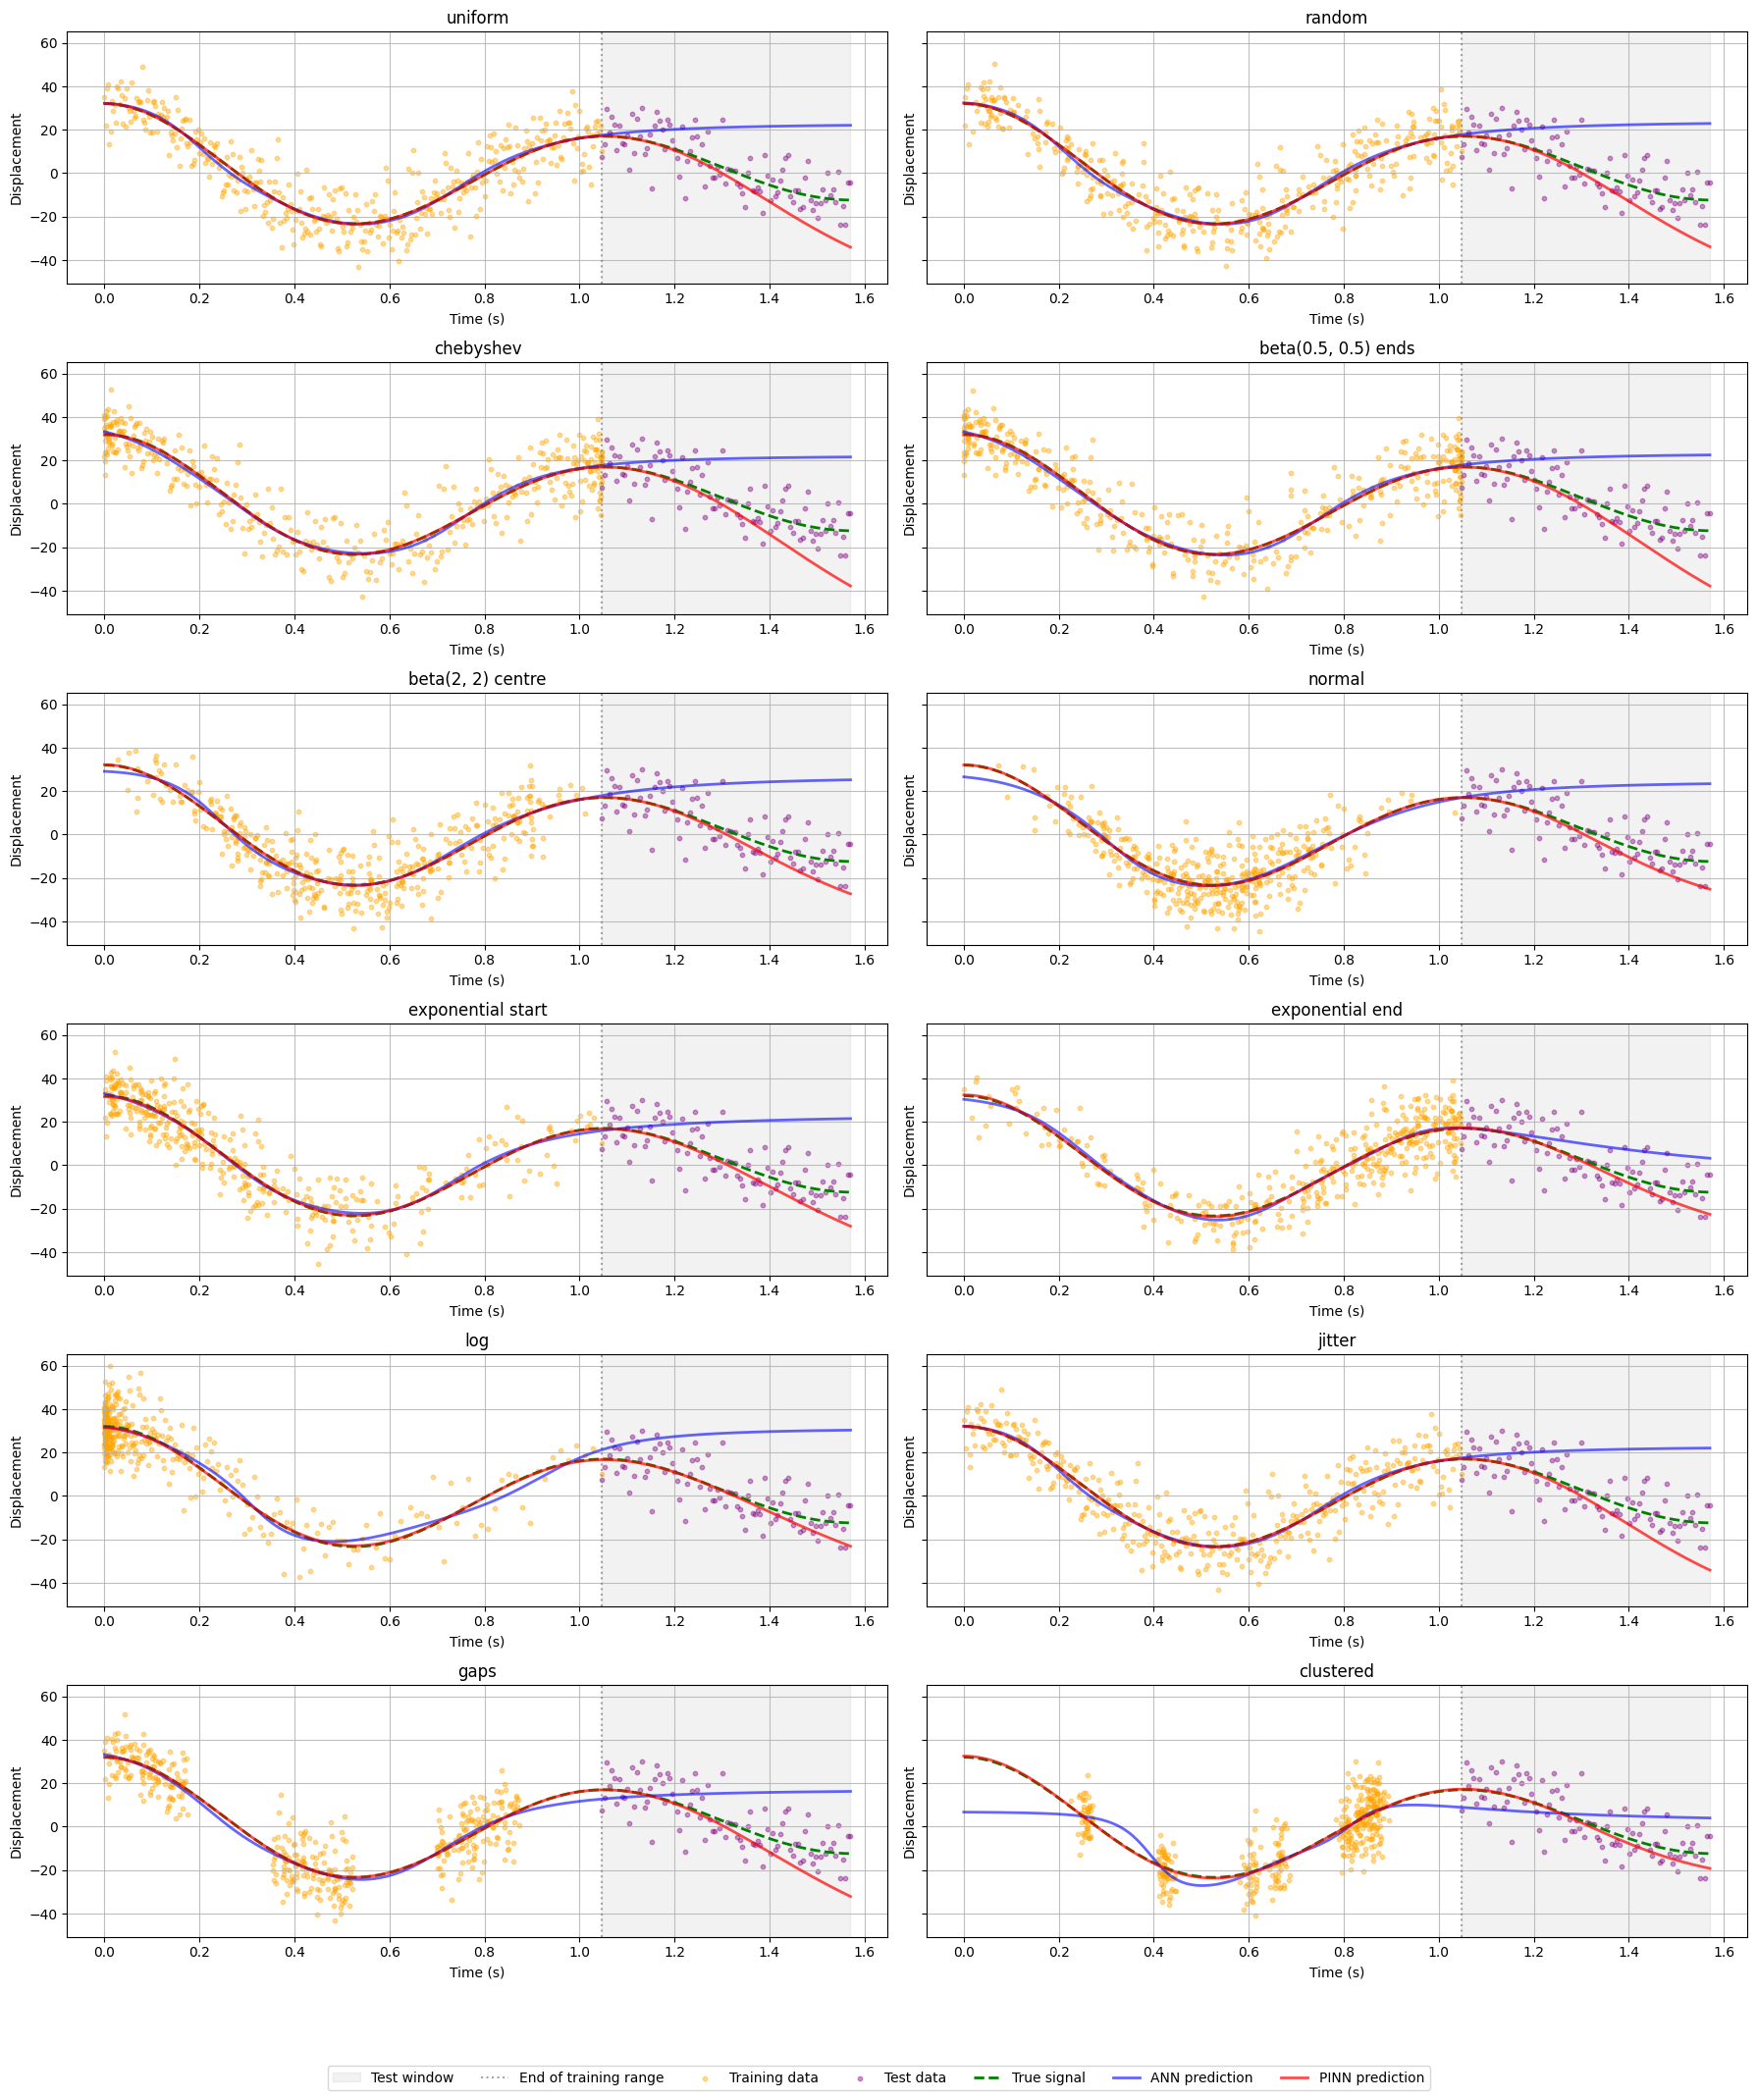

In [25]:
plot_predictions_grid(results, ncols=2)

#### Inspect one scheme in detail
Every entry of `results` is an `ExperimentResult`, so all the plots of Section 3 work on it.

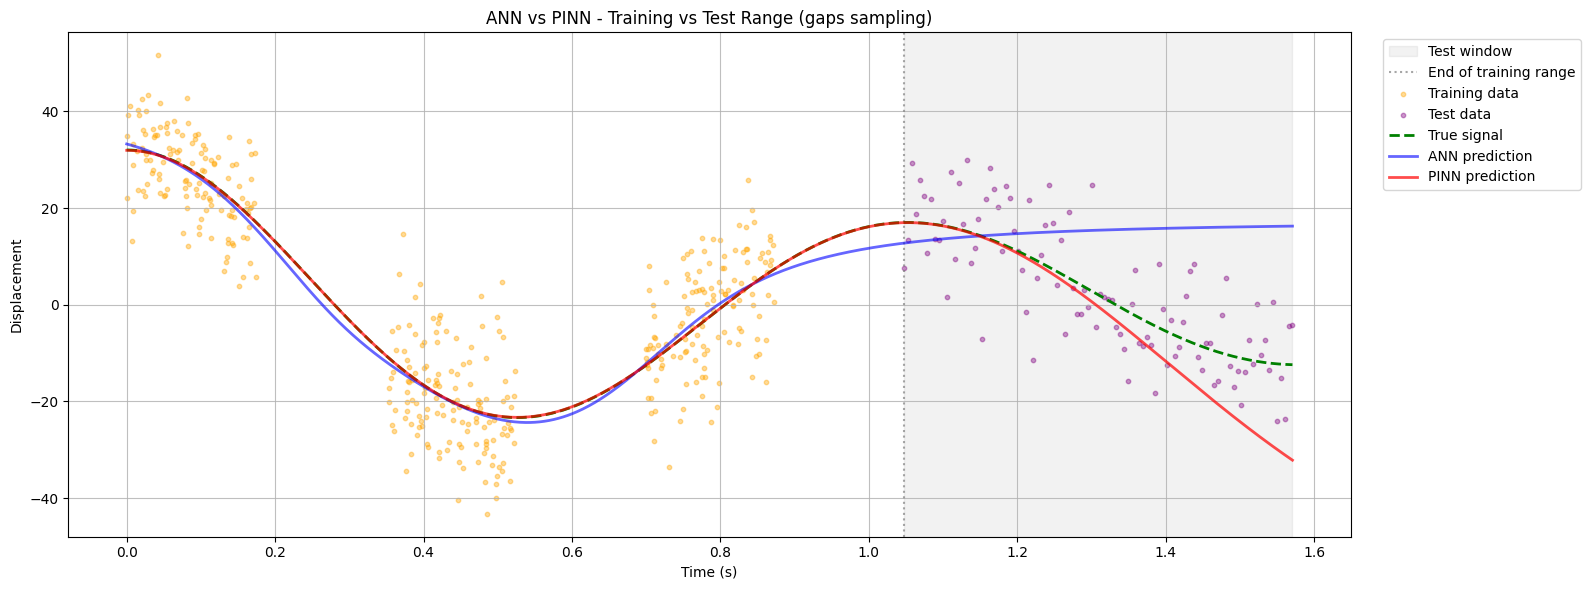

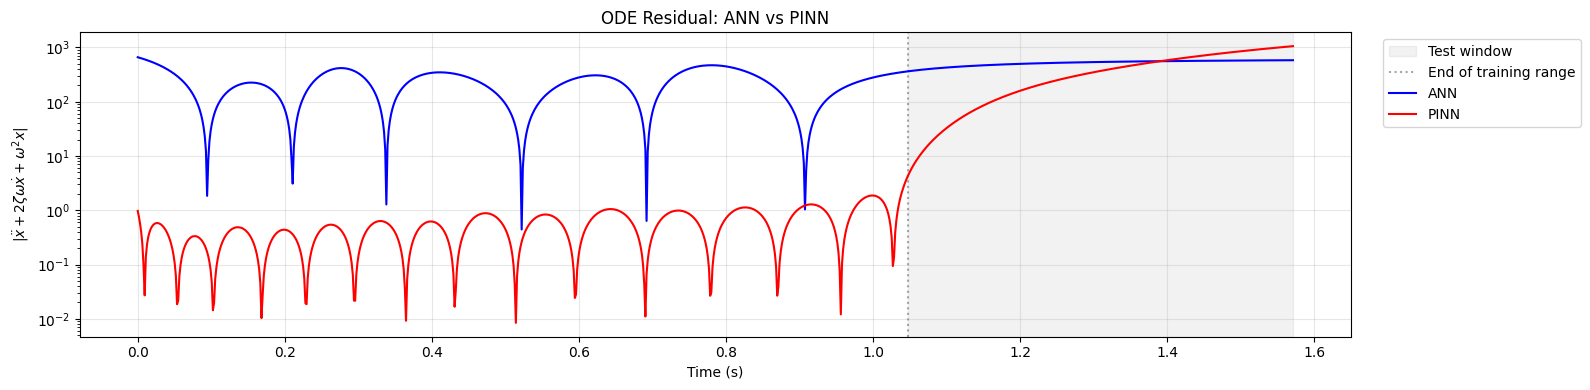

ANN                                PINN           \
                       MSE     RMSE      MAE      R2       MSE     RMSE   
Train (vs noisy)   82.8625   9.1029   7.2158  0.8197   83.3632   9.1303   
Train (vs true)     0.5786   0.7606   0.6469  0.9985    0.0023   0.0477   
Test (vs noisy)   357.1452  18.8983  15.9503 -0.8791  140.8243  11.8669   
Test (vs true)    295.0828  17.1780  13.9419 -1.7095   59.3949   7.7068   

                                  
                     MAE      R2  
Train (vs noisy)  7.2749  0.8186  
Train (vs true)   0.0419  1.0000  
Test (vs noisy)   9.2946  0.2591  
Test (vs true)    5.0784  0.4546

In [26]:
r = results["gaps"]
plot_predictions_full(r)
plot_ode_residual(r)
display(r.metrics.round(4))